Check Dataset

In [70]:
from pathlib import Path

dataset_path = Path("D:\\UOM\\Sem 5\\Pattern\\Assignment03\\RocogniX_Classification_Assignment\\split")

for split in ["train", "validation", "test"]:
    folder = dataset_path / split

    files = list(folder.rglob("*.pgm"))

    print(f"{split}: {len(files)} images")

    print("Example files:")
    for f in files[:5]:
        print("  ", f)

    print()

train: 436 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_sad_sunglasses_2.pgm

validation: 93 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_right_angry_sunglasses

In [71]:
from PIL import Image

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    print(f"\n{split}")

    for f in files[:5]:
        img = Image.open(f)
        print(f.name, "→", img.size, img.mode)


train
an2i_left_happy_open_2.pgm → (64, 60) L
an2i_left_happy_sunglasses_2.pgm → (64, 60) L
an2i_left_neutral_open_2.pgm → (64, 60) L
an2i_left_neutral_sunglasses_2.pgm → (64, 60) L
an2i_left_sad_sunglasses_2.pgm → (64, 60) L

validation
an2i_left_angry_open_2.pgm → (64, 60) L
an2i_left_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_neutral_sunglasses_2.pgm → (64, 60) L

test
an2i_left_sad_open_2.pgm → (64, 60) L
an2i_up_angry_sunglasses_2.pgm → (64, 60) L
an2i_up_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_sad_open_2.pgm → (64, 60) L
at33_left_angry_open_2.pgm → (64, 60) L


In [72]:
from collections import Counter

poses = ["straight", "left", "right", "up"]

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    counts = Counter()

    for f in files:
        parts = f.stem.split("_")

        # filename:
        # userid_pose_expression_eyes_scale
        pose = parts[1]

        counts[pose] += 1

    print(f"\n{split}:")
    
    for pose in poses:
        print(f"{pose:8s}: {counts[pose]}")


train:
straight: 109
left    : 105
right   : 113
up      : 109

validation:
straight: 26
left    : 25
right   : 23
up      : 19

test:
straight: 21
left    : 27
right   : 19
up      : 28


Load Dataset into NumPy

In [73]:
from pathlib import Path
from PIL import Image
import numpy as np

# Dataset path
DATASET_PATH = Path("../split")

# Class mapping
CLASS_TO_INDEX = {
    "straight": 0,
    "left": 1,
    "right": 2,
    "up": 3
}

CLASS_NAMES = list(CLASS_TO_INDEX.keys())

def load_dataset(split):
    folder = DATASET_PATH / split

    images = []
    labels = []

    files = sorted(folder.glob("*.pgm"))

    for file in files:
        # Extract pose from filename
        # Example: an2i_left_happy_open_2.pgm
        pose = file.stem.split("_")[1]

        # Convert pose to numerical label
        label = CLASS_TO_INDEX[pose]

        # Load grayscale image
        image = np.array(Image.open(file), dtype=np.float32)

        # Normalize pixels: 0-255 -> 0-1
        image /= 255.0

        # Add channel dimension: (60,64) -> (60,64,1)
        image = np.expand_dims(image, axis=-1)

        images.append(image)
        labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int64)

In [74]:
# Load datasets
X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")


# Display information
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)

print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

print("\nPixel range:", X_train.min(), "to", X_train.max())
print("Classes:", CLASS_TO_INDEX)

X_train: (436, 60, 64, 1)
y_train: (436,)
X_val:   (93, 60, 64, 1)
y_val:   (93,)
X_test:  (95, 60, 64, 1)
y_test:  (95,)

Pixel range: 0.0 to 0.9882353
Classes: {'straight': 0, 'left': 1, 'right': 2, 'up': 3}


In [75]:
import os
print(os.getcwd())
print("Dataset path:", DATASET_PATH)

d:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\Model_B
Dataset path: ..\split


Visualise the loaded data

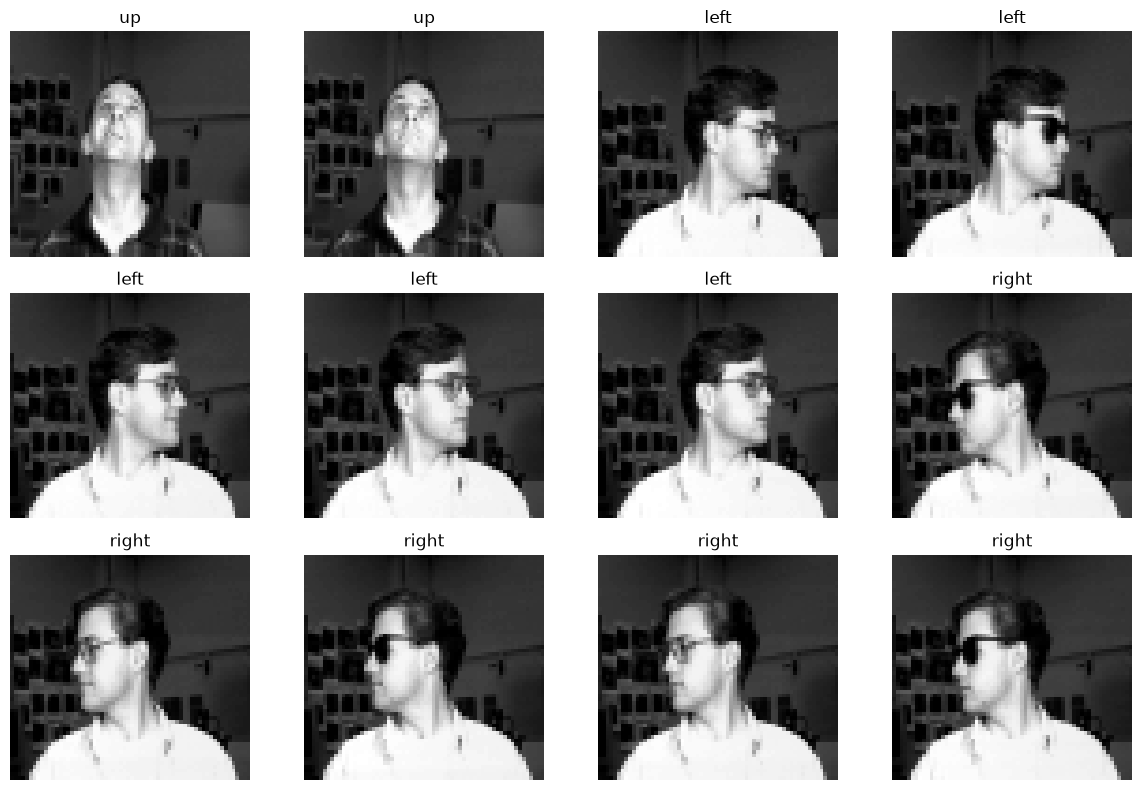

In [76]:
import matplotlib.pyplot as plt

# Number of images to display
num_images = 12
start_image_index = 60  # Starting index for displaying images

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_train[i+start_image_index].squeeze(), cmap="gray")
    plt.title(CLASS_NAMES[y_train[i+start_image_index]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Model B Implementation

In [79]:
from tensorflow.keras import layers, models

# model_B2 = models.Sequential([
#     layers.Input(shape=(60, 64, 1)),

#     layers.SeparableConv2D(32, 3, padding="same", activation="relu"),
#     layers.MaxPooling2D(2),

#     layers.SeparableConv2D(64, 3, padding="same", activation="relu"),
#     layers.MaxPooling2D(2),

#     layers.SeparableConv2D(128, 3, padding="same", activation="relu"),
#     layers.MaxPooling2D(2),

#     layers.SeparableConv2D(192, 3, padding="same", activation="relu"),

#     layers.GlobalAveragePooling2D(),

#     layers.Dense(128, activation="relu"),
#     layers.Dropout(0.3),
#     layers.Dense(4, activation="softmax")
# ])

#Model B2 with Batch Normalization and ReLU activation
model_B = models.Sequential([
    layers.Input(shape=(60, 64, 1)),

    # Block 1
    layers.SeparableConv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(2),

    # Block 2
    layers.SeparableConv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(2),

    # Block 3
    layers.SeparableConv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(2),

    # Block 4
    layers.SeparableConv2D(192, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

model_B.summary()
print("Total parameters:", model_B.count_params())



# Compile Model B
from tensorflow.keras.optimizers import Adam

model_B.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)




# Train Model B
history_B = model_B.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)



Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_51             │ (None, 60, 64, 32)     │            41 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 60, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_20 (ReLU)                 │ (None, 60, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_52             │ (None, 30, 32, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 30, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_21 (ReLU)                 │ (None, 30, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_53             │ (None, 15, 16, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 15, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_22 (ReLU)                 │ (None, 15, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_54             │ (None, 7, 8, 192)      │        25,728 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 7, 8, 192)      │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_23 (ReLU)                 │ (None, 7, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,757 (249.05 KB)

 Trainable params: 62,925 (245.80 KB)

 Non-trainable params: 832 (3.25 KB)

Total parameters: 63757
Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - accuracy: 0.2661 - loss: 1.4148 - val_accuracy: 0.2688 - val_loss: 1.3862
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.3211 - loss: 1.3692 - val_accuracy: 0.2473 - val_loss: 1.3864
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.3670 - loss: 1.3476 - val_accuracy: 0.2473 - val_loss: 1.3865
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.3234 - loss: 1.3591 - val_accuracy: 0.2473 - val_loss: 1.3866
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.3991 - loss: 1.3176 - val_accuracy: 0.2473 - val_loss: 1.3866
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.4197 - loss: 1.2982 - val_accuracy: 0.2473 - val_loss: 1.3866
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.4243 - loss: 1.2861 - val_accuracy: 0.2473 - val_loss: 1.3867
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.4702 - loss: 

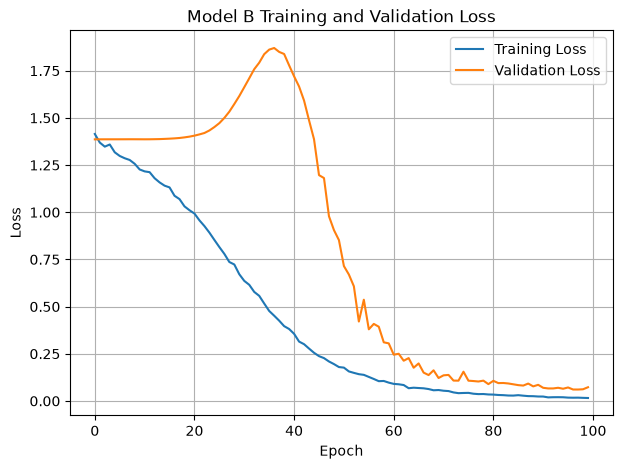

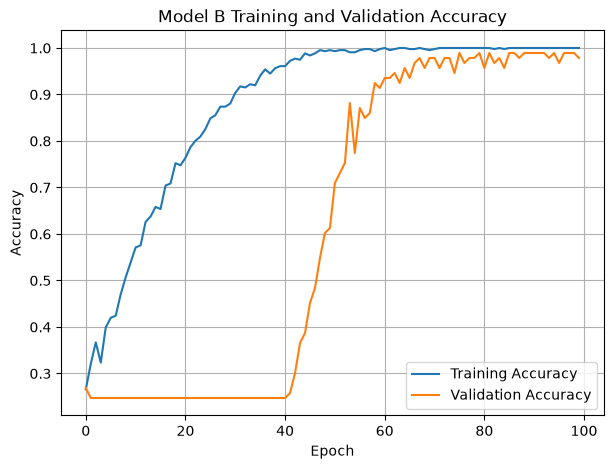

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9368 - loss: 0.2041
Test Loss: 0.2041
Test Accuracy: 0.9368
Test Accuracy: 93.68%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


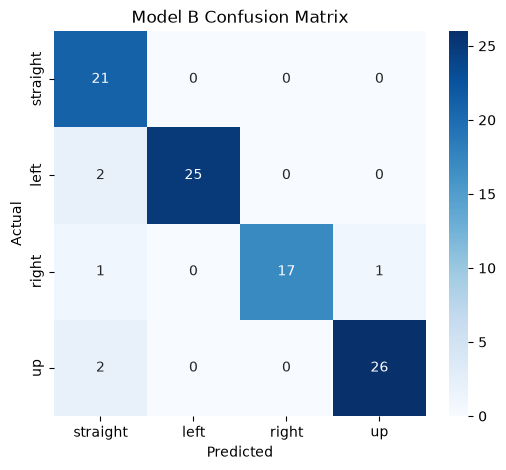

              precision    recall  f1-score   support

    straight     0.8077    1.0000    0.8936        21
        left     1.0000    0.9259    0.9615        27
       right     1.0000    0.8947    0.9444        19
          up     0.9630    0.9286    0.9455        28

    accuracy                         0.9368        95
   macro avg     0.9427    0.9373    0.9363        95
weighted avg     0.9466    0.9368    0.9384        95



In [80]:
import matplotlib.pyplot as plt

# Model B Performance Plots
plt.figure(figsize=(7,5))
plt.plot(history_B.history["loss"], label="Training Loss")
plt.plot(history_B.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(7,5))
plt.plot(history_B.history["accuracy"], label="Training Accuracy")
plt.plot(history_B.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()



# Evaluate Model B on Test Set
test_loss, test_accuracy = model_B.evaluate(
    X_test, y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")


# Genarate Predictions
y_pred_prob = model_B.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model B Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))



In [81]:
model_B.save("model_B.keras")